In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_random_sampled.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  58 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,...,cat_wrong_task,cat_too_generic,cat_truncated_incomplete,cat_correct_domain,cat_correct_task,cat_methodology_partially_correct,cat_scientific_language,cat_coherent_structure,num_of_neighbors,is_error
0,769,2942669846,Reinforcement learning usually makes use of nu...,"In this study, we combine insights from variou...",0.2544,0.0356,0.1484,0.8236,0.8317,0.8276,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4,False
1,2012,2913127348,Gatherings of thousands to millions of people ...,This paper presents a novel approach to docume...,0.1976,0.0000,0.1107,0.8398,0.8197,0.8296,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,8,False
2,3364,2942522480,"Recently, a method called the Mutual Informati...",This paper proposes a voice-controlled e-comme...,0.2437,0.0361,0.1362,0.8207,0.8112,0.8159,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,4,False


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

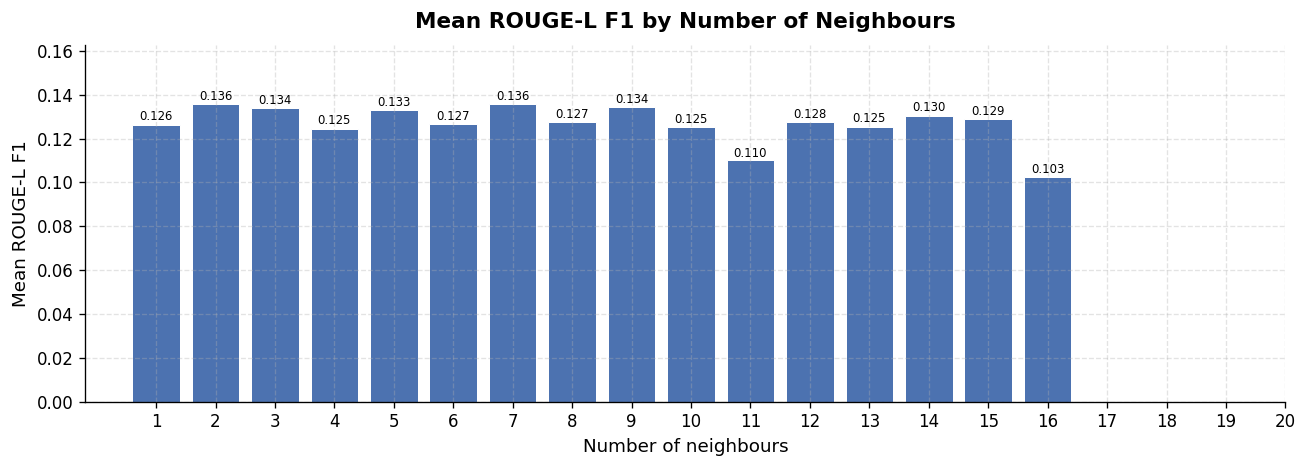

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

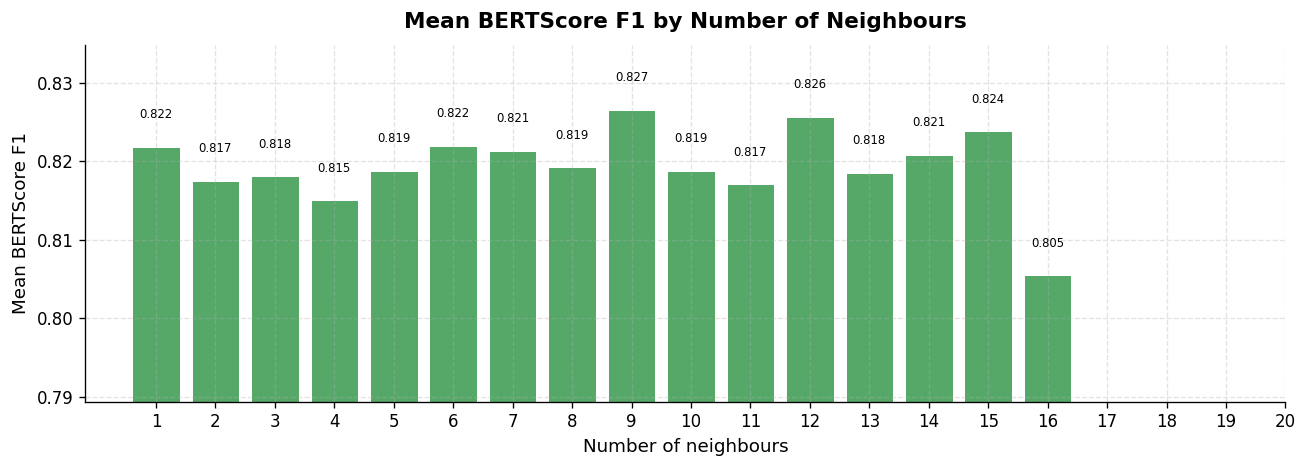

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

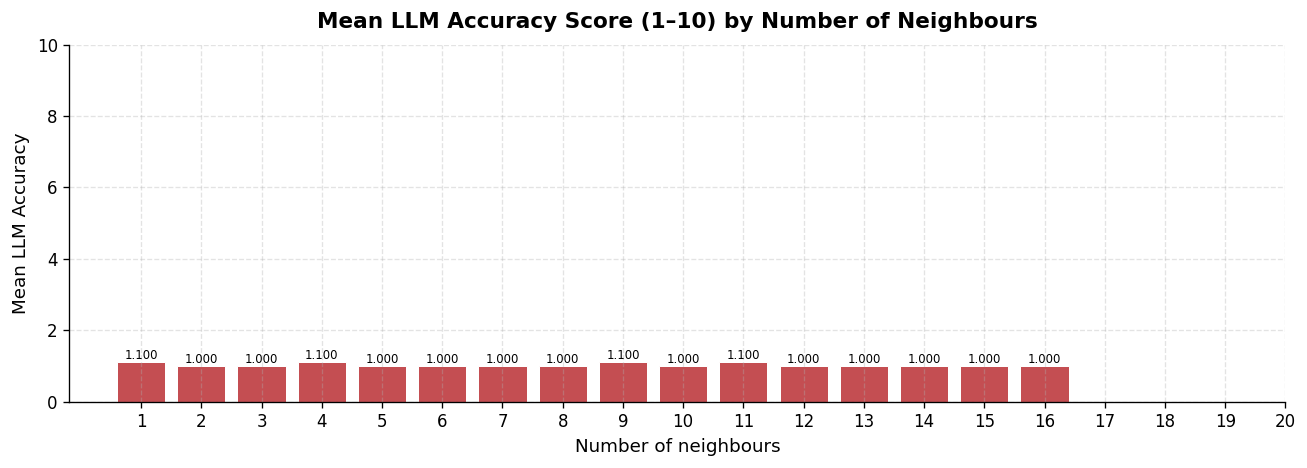

In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

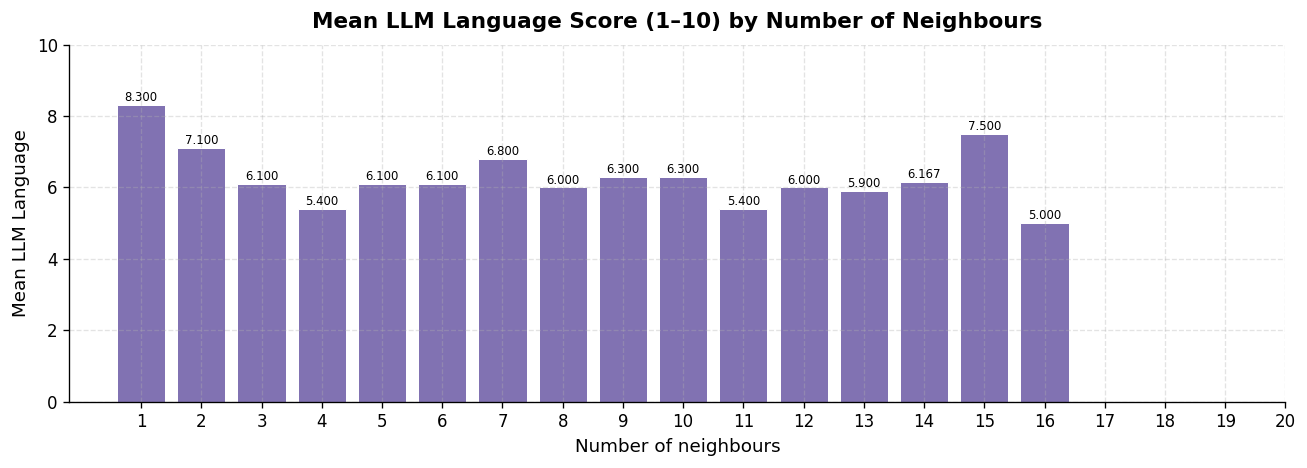

In [6]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

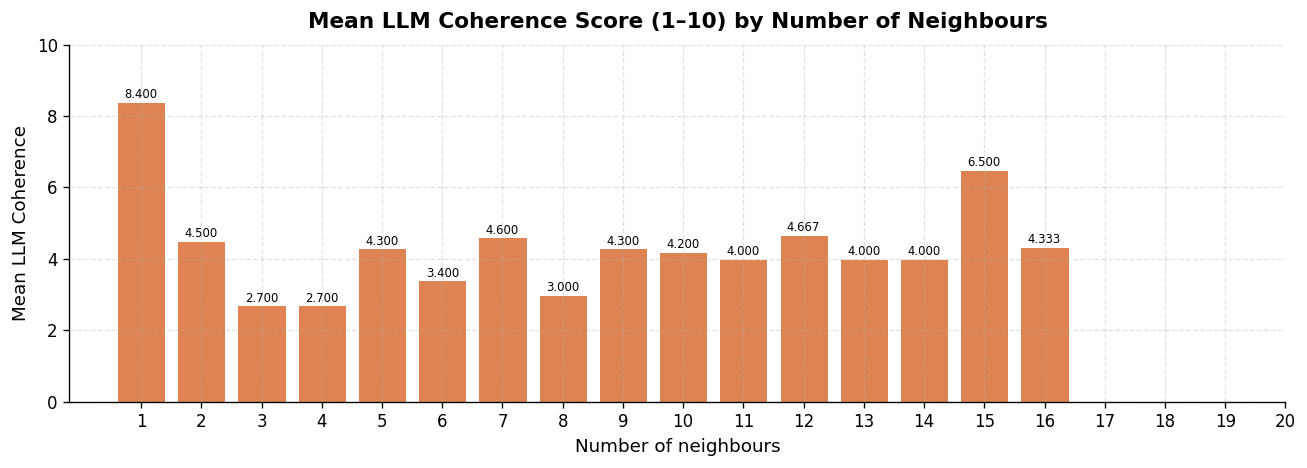

In [7]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

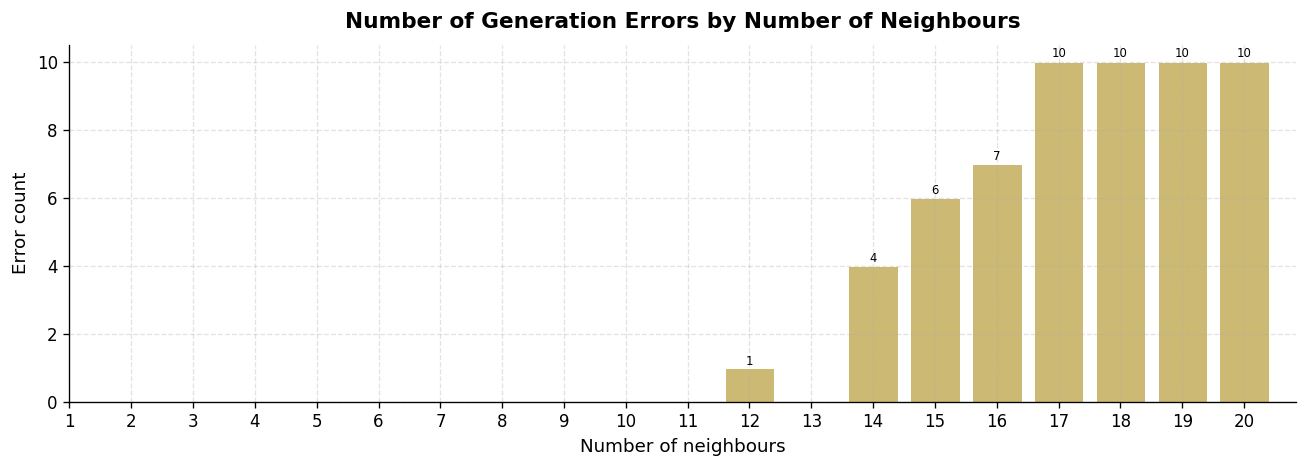

In [8]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [9]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_87063/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,769,"Reinforcement learning usually makes use of numerical rewards, which have nice properties but also come with drawbacks and difficulties. Using rewards on an ordinal scale (ordinal rewards) is an alternative to numerical rewards that has received more attention in recent years. In this paper, a general approach to adapting reinforcement learning problems to the use of ordinal rewards is presented and motivated. We show how to convert common reinforcement learning algorithms to an ordinal variation by the example of Q-learning and introduce Ordinal Deep Q-Networks, which adapt deep reinforcement learning to ordinal rewards. Additionally, we run evaluations on problems provided by the OpenAI Gym framework, showing that our ordinal variants exhibit a performance that is comparable to the numerical variations for a number of problems. We also give first evidence that our ordinal variant is able to produce better results for problems with less engineered and simpler-to-design reward signals.","In this study, we combine insights from various sources to explore the impact of open access (OA) articles on citation, article views, and social media attention. Using data from 1761 Nature Communications articles published between 2012 and 2013, we confirm the OA citation advantage and find that OA papers have sustained and steady downloads compared to non-OA papers. Additionally, we analyze the outage capacity of slow fading relay channels in the low SNR and low outage probability regime, showing that a modified Amplify-Forward protocol achieves the outage capacity without prior channel knowledge. Finally, we investigate the limitations of algebraic approaches to graph isomorphism testing and compare them to linear and semidefinite programming approaches, characterizing the power of the Weisfeiler-Lehman algorithm in terms of an algebraic proof system.",1.0
1,112227,"The TrustZone technology, available in the vast majority of recent ARM processors, allows the execution of code inside a so-called secure world. It effectively provides hardware-isolated areas of the processor for sensitive data and code, i.e., a trusted execution environment (TEE). The OP-TEE framework provides a collection of toolchain, open-source libraries and secure kernel specifically geared to develop applications for TrustZone. This paper presents an in-depth performance- and energy-wise study of TrustZone using the OP-TEE framework, including secure storage and the cost of switching between secure and unsecure worlds, using emulated and hardware measurements.","This paper presents a new application of molecular communication networks, focusing on boosting the throughput while minimizing the emitted number of molecules. The proposed method involves using randomized prediction games to improve the security of learning algorithms against evasion attacks. The study also explores the multiparty communication complexity of testing triangle-freeness in graphs, using the coordinator model where players receive private inputs and a coordinator communicates with all players. The paper shows that a protocol using $\tilde{O}(k\sqrt{n})$ bits is sufficient for simultaneous communication when the average degree is $d=O(\sqrt{n})$, and $\tilde{O}(k(nd)^{1/3})$ bits are required when $d=\Omega(\sqrt{n})$. For higher degrees, the paper provides evidence of the hardness of finding an edge that participates in a triangle, even when promised that at least a constant fraction of the edges must be removed to make the graph triangle-free.",1.0
2,17927,"Abstract To improve the performance of Intensive Care Units (ICUs), the field of bio-statistics has developed scores which try to predict the likelihood of negative outcomes. These help evaluate the effectiveness of treatments and clinical practice, and also help to identify patients with unexpected outcomes. However, they have been shown by several studies to offer sub-optimal 

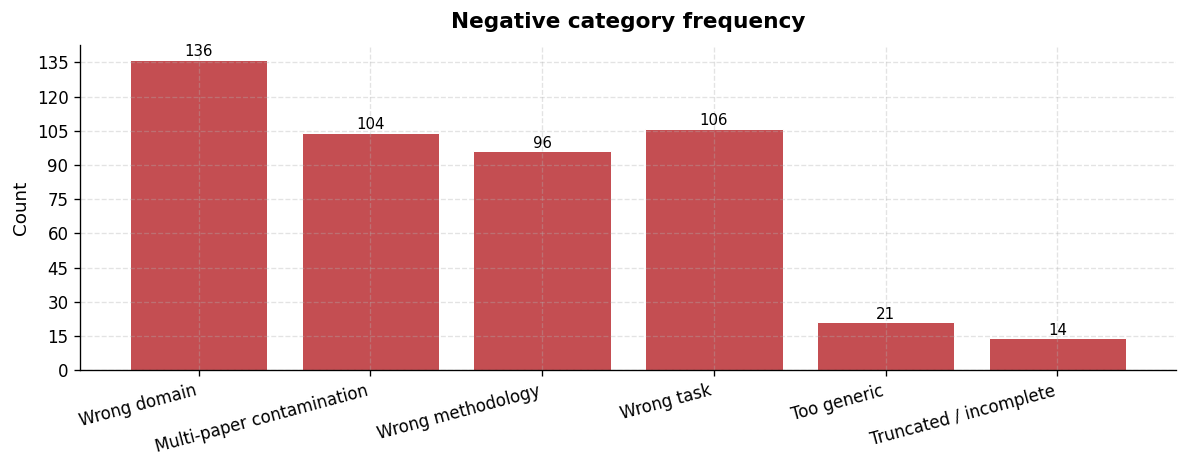

In [10]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


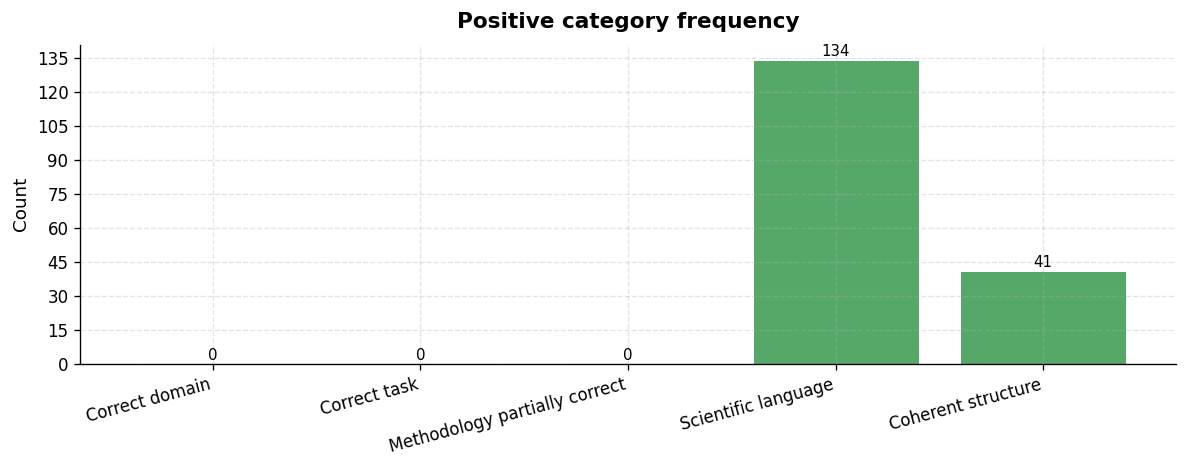

In [11]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()